In [1]:
from diffusers import StableDiffusionControlNetPipeline, ControlNetModel
import torch
import cv2
from PIL import Image
import numpy as np
import matplotlib.pyplot as plt
import os
os.environ["KMP_DUPLICATE_LIB_OK"] = "TRUE"

In [2]:
controlnet = ControlNetModel.from_pretrained(
    "lllyasviel/sd-controlnet-scribble",
    torch_dtype=torch.float16
).to("cuda")

pipe = StableDiffusionControlNetPipeline.from_pretrained(
    "runwayml/stable-diffusion-v1-5",
    controlnet=controlnet,
    safety_checker=None,
    torch_dtype=torch.float16
).to("cuda")


/usr/local/lib/python3.12/dist-packages/huggingface_hub/utils/_auth.py:94: UserWarning: 
The secret `HF_TOKEN` does not exist in your Colab secrets.
To authenticate with the Hugging Face Hub, create a token in your settings tab (https://huggingface.co/settings/tokens), set it as secret in your Google Colab and restart your session.
You will be able to reuse this secret in all of your notebooks.
Please note that authentication is recommended but still optional to access public models or datasets.
  warnings.warn(


config.json:   0%|          | 0.00/920 [00:00<?, ?B/s]

diffusion_pytorch_model.safetensors:   0%|          | 0.00/1.45G [00:00<?, ?B/s]

model_index.json:   0%|          | 0.00/541 [00:00<?, ?B/s]

Fetching 13 files:   0%|          | 0/13 [00:00<?, ?it/s]

...

config.json:   0%|          | 0.00/547 [00:00<?, ?B/s]

unet/diffusion_pytorch_model.safetensors:   0%|          | 0.00/3.44G [00:00<?, ?B/s]

vae/diffusion_pytorch_model.safetensors:   0%|          | 0.00/335M [00:00<?, ?B/s]

Loading pipeline components...:   0%|          | 0/6 [00:00<?, ?it/s]

`torch_dtype` is deprecated! Use `dtype` instead!
You have disabled the safety checker for <class 'diffusers.pipelines.controlnet.pipeline_controlnet.StableDiffusionControlNetPipeline'> by passing `safety_checker=None`. Ensure that you abide to the conditions of the Stable Diffusion license and do not expose unfiltered results in services or applications open to the public. Both the diffusers team and Hugging Face strongly recommend to keep the safety filter enabled in all public facing circumstances, disabling it only for use-cases that involve analyzing network behavior or auditing its results. For more information, please have a look at https://github.com/huggingface/diffusers/pull/254 .


In [3]:
def load_sketch(path):
    img = cv2.imread(path)
    img = cv2.cvtColor(img, cv2.COLOR_BGR2GRAY)
    img = cv2.resize(img, (512, 512))
    img = cv2.Canny(img, 250 ,250)
    img = Image.fromarray(img)
    return img


In [7]:
import os
import numpy as np
import random
from PIL import Image
import requests

# Cartella output
os.makedirs("quickdraw_samples", exist_ok=True)

# 1. Scegli una classe (es. 'cat')
CLASS_NAME = "cat"   # puoi cambiarla

# 2. Scarica il file .npy della classe
url = f"https://storage.googleapis.com/quickdraw_dataset/full/numpy_bitmap/{CLASS_NAME}.npy"
fname = f"{CLASS_NAME}.npy"

print("Downloading:", url)
r = requests.get(url)
open(fname, "wb").write(r.content)

# 3. Carica le immagini (28x28)
data = np.load(fname)

print("Loaded images:", data.shape)

# 4. Prendi 10 immagini a caso
indices = random.sample(range(len(data)), 10)

for i, idx in enumerate(indices):
    img = data[idx].reshape(28, 28)
    img = Image.fromarray(img.astype("uint8"), mode="L")
    img.save(f"quickdraw_samples/{CLASS_NAME}_{i}.png")

print("Saved 10 images in quickdraw_samples/")


Downloading: https://storage.googleapis.com/quickdraw_dataset/full/numpy_bitmap/cat.npy
Loaded images: (123202, 784)
Saved 10 images in quickdraw_samples/


/tmp/ipython-input-1103808408.py:31: DeprecationWarning: 'mode' parameter is deprecated and will be removed in Pillow 13 (2026-10-15)
  img = Image.fromarray(img.astype("uint8"), mode="L")


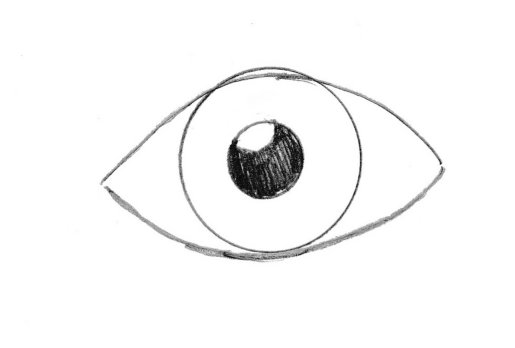

In [51]:
from PIL import Image
import matplotlib.pyplot as plt

# Carica l'immagine
img = Image.open("eye.jpg").convert("L")

# Mostra
plt.imshow(img, cmap="gray")
plt.axis("off")
plt.show()


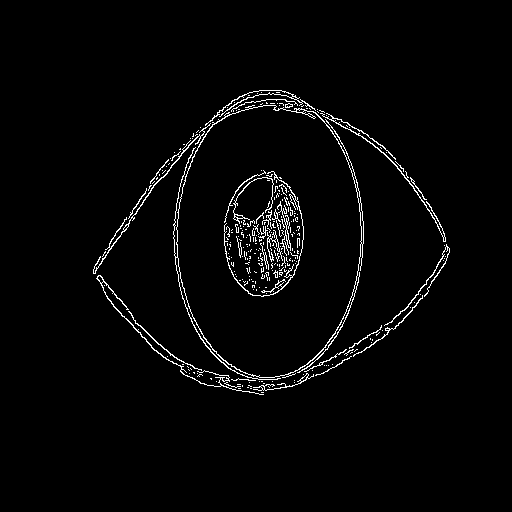

In [52]:
load_sketch("eye.jpg")

In [115]:
def generate_controlnet(sketch_path, prompt="a realistic version the sketch"):
    sketch = load_sketch(sketch_path)

    negative_prompt = (
        "metal, glossy, plastic, alien texture, creepy, horror, shiny skin, scales, armor, robotic, "
        "deformed, blur, noise, extra limbs, distorted colors"
    )
    result = pipe(
        prompt,
        negative_prompt=negative_prompt,
        image=sketch,
        num_inference_steps=10,
        guidance_scale=8, #6-9
        controlnet_conditioning_scale=1.3 #1.0-1.5
    )

    return result.images[0]


In [116]:
prompt = (
    "Make the eye ultra-realistic")

  0%|          | 0/10 [00:00<?, ?it/s]

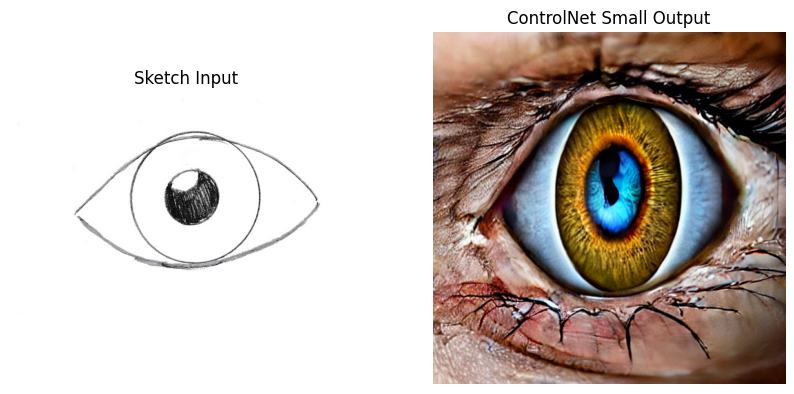

In [129]:
sketch_path = "eye.jpg"

output = generate_controlnet(sketch_path, prompt=prompt)

plt.figure(figsize=(10,5))
plt.subplot(1,2,1)
plt.title("Sketch Input")
plt.imshow(Image.open(sketch_path))
plt.axis("off")

plt.subplot(1,2,2)
plt.title("ControlNet Small Output")
plt.imshow(output)
plt.axis("off")

plt.show()


In [130]:
from PIL import Image
import torch
import numpy as np
import os
import imageio
import torch

generator = torch.Generator().manual_seed(12345)


def generate_controlnet_frames(sketch_path, prompt="a realistic version of the sketch", steps=50):
    sketch = load_sketch(sketch_path)
    frames = []

    def save_step_callback(pipe, step, timestep, callback_kwargs):
        latents = callback_kwargs["latents"]

        # Decodifica immagine da latents
        with torch.no_grad():
            image = pipe.decode_latents(latents)
            pil_img = pipe.numpy_to_pil(image)[0]

        frames.append(pil_img)
        return {"latents": latents}  # important!

    result = pipe(
        prompt,
        negative_prompt="metal, glossy, plastic, creepy, deformed, blur",
        image=sketch,
        num_inference_steps=steps,
        guidance_scale=8,
        controlnet_conditioning_scale=1.3,
        generator=torch.Generator().manual_seed(12345),
        callback_on_step_end=save_step_callback,
        callback_on_step_end_tensor_inputs=["latents"]
    )

    return frames, result.images[0]


def save_frames(frames, folder="frames"):
    os.makedirs(folder, exist_ok=True)
    for i, frame in enumerate(frames):
        frame.save(f"{folder}/frame_{i:04d}.png")


def create_video_from_frames(folder="frames", output="generation.mp4", fps=10):
    frames = []
    file_list = sorted(os.listdir(folder))

    for f in file_list:
        if f.endswith(".png"):
            frames.append(imageio.imread(os.path.join(folder, f)))

    imageio.mimsave(output, frames, fps=fps)
    print("Video saved:", output)


In [131]:
frames, final_image = generate_controlnet_frames("eye.jpg", prompt="Make the eye ultra-realistic", steps=100)
save_frames(frames, folder="frames_eye")
create_video_from_frames(folder="frames_eye", output="eye_generation.mp4", fps=20)

  0%|          | 0/100 [00:00<?, ?it/s]

/tmp/ipython-input-3569664084.py:53: DeprecationWarning: Starting with ImageIO v3 the behavior of this function will switch to that of iio.v3.imread. To keep the current behavior (and make this warning disappear) use `import imageio.v2 as imageio` or call `imageio.v2.imread` directly.
  frames.append(imageio.imread(os.path.join(folder, f)))


Video saved: eye_generation.mp4
